# Magnetogram (SDO/HMI) features, path (i) (not built)

**The question:** do generic numbers from the photospheric magnetic field, fed straight into the
speed models, improve the forecast?

**Data:** SDO/HMI quick-look browse magnetograms (512 px JPEGs, grey = line-of-sight field),
2016-10 → 2026-10, one per 6-hourly cut-off t0 − 1 h, the same product as live
(`training.pull_hmi_images`). Each image becomes a 10° × 10° heliographic grid; per image, seven
signals mainly over the central-meridian strip (`feature_engineering.magnetogram.signals`), read
like the AIA strips (`feature_engineering.windows`).

**The test** (`python -m training.magnetogram_features`): four feature sets added to the hybrid's
trees, four lead-aligned terms added to the linear model. Six yearly walk-forward folds
(2019-10 → 2025-10); score: per-run mean TIMSE / persistence, geometric mean over folds; also on CME
runs and the rest. The eval year is not used.

**Keep rule (set before running):** more than 1% better on the six-fold score, winning at least
4 of 6 folds.

1. The signals
2. Scores
3. By fold
4. CME runs and the rest
5. Findings

## 1. The signals: coverage, the solar cycle, and what they track

14636 cut-offs, 95.2% with a usable image


cutoff,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
coverage,1.0,1.0,1.0,0.99,1.0,1.0,1.0,1.0,0.91,0.71,0.89


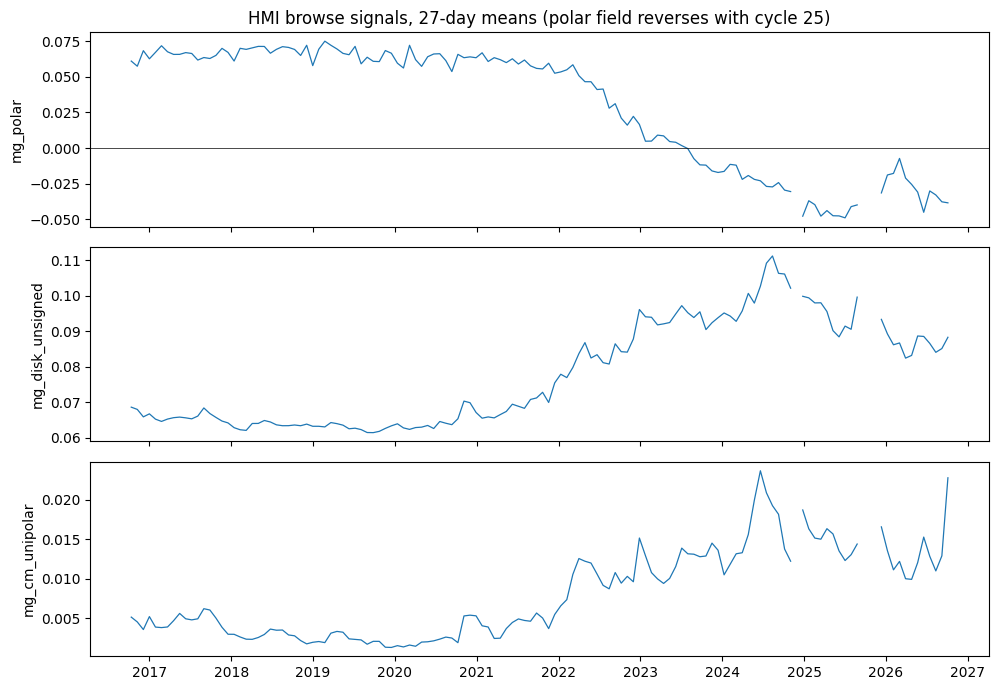

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import magnetogram_features as m
from training import pull_hmi_images as ph
from training import regime_models as rm

signals = ph.load_signals()
usable = signals["mg_cm_unipolar"].notna().mean()
print(f"{len(signals)} cut-offs, {usable:.1%} with a usable image")
display(signals.groupby(signals.index.year)["mg_cm_unipolar"].apply(lambda v: v.notna().mean())
        .rename("coverage").to_frame().T.round(2))
monthly = signals.resample("27D").mean()
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, s in zip(axes, ("mg_polar", "mg_disk_unsigned", "mg_cm_unipolar"), strict=True):
    ax.plot(monthly.index, monthly[s], lw=0.9)
    ax.set_ylabel(s)
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set_title("HMI browse signals, 27-day means (polar field reverses with cycle 25)")
plt.tight_layout()

In [2]:
# correlation with the AIA coronal-hole fraction and with the mean speed 73-96 h later,
# raw and with an 81-day running mean removed (the solar-cycle trend)
data = rm.Data()
cols = [f"{s}_at_0h" for s in ("mg_cm_signed", "mg_cm_unipolar", "mg_cm_unsigned",
                               "mg_cm_strong", "mg_cm_imbalance", "mg_disk_unsigned", "mg_polar")]
t = m.magnetogram_table(data.runs6, cols)
t["ch_cm_at_0h"] = data.table.loc[data.runs6, "ch_cm_at_0h"].to_numpy()
speed = pd.Series(data.values, index=data.series.index)
t["speed"] = speed.rolling(24).mean().shift(-96).reindex(data.runs6).to_numpy()
t = t.dropna()
detrended = t - t.rolling(324, center=True, min_periods=100).mean()
corr = pd.DataFrame({
    "ch_cm (raw)": t.corr()["ch_cm_at_0h"], "speed (raw)": t.corr()["speed"],
    "ch_cm (detrended)": detrended.corr()["ch_cm_at_0h"],
    "speed (detrended)": detrended.corr()["speed"]}).drop("speed")
print(f"{len(t)} runs with both signals")
display(corr.round(2))

6658 runs with both signals


,ch_cm (raw),speed (raw),ch_cm (detrended),speed (detrended)
mg_cm_signed_at_0h,0.03,-0.06,0.06,-0.04
mg_cm_unipolar_at_0h,-0.10,0.14,0.02,0.03
mg_cm_unsigned_at_0h,-0.25,0.14,-0.15,-0.05
mg_cm_strong_at_0h,-0.25,0.14,-0.16,-0.06
mg_cm_imbalance_at_0h,0.15,0.23,0.23,0.16
mg_disk_unsigned_at_0h,-0.21,0.19,-0.05,0.01
mg_polar_at_0h,0.07,-0.23,-0.00,0.02
ch_cm_at_0h,1.00,0.31,1.00,0.32


## 2. Scores

In [3]:
df = pd.read_csv(m.EXPERIMENTS / "magnetogram_features.csv").set_index("fold")


def geo(c):
    return float(np.exp(np.log(df[c]).mean()))


rows = {}
for name in m.variant_names()[1:]:
    ref = "hybrid shipped" if name.startswith("hybrid") else "linear shipped"
    rows[name] = {"score": geo(name), "vs shipped": geo(name) / geo(ref) - 1,
                  "folds won": int((df[name] < df[ref]).sum()),
                  "CME runs": geo(f"{name} cme") - 1, "other runs": geo(f"{name} other") - 1}
for ref in ("hybrid shipped", "linear shipped"):
    rows[ref] = {"score": geo(ref)}
summary = pd.DataFrame(rows).T.sort_values("score")
summary["keep"] = (summary["vs shipped"] < -0.01) & (summary["folds won"] >= 4)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(summary)

,score,vs shipped,folds won,CME runs,other runs,keep
hybrid + unipolar,0.4175,-0.0036,4.0000,0.0005,-0.0045,False
hybrid + cm + polarity,0.4179,-0.0025,3.0000,0.0006,-0.0009,False
hybrid shipped,0.4190,NaN,NaN,NaN,NaN,False
hybrid + cm,0.4199,0.0021,2.0000,0.0082,0.0036,False
hybrid + cm + disk + polar,0.4217,0.0066,2.0000,0.0171,0.0035,False
linear + mg_cm_imbalance_lead_72h,0.4254,-0.0004,4.0000,0.0234,-0.0060,False
linear + mg_cm_strong_lead_72h,0.4254,-0.0004,4.0000,-0.0037,0.0111,False
linear + mg_cm_unsigned_lead_72h,0.4254,-0.0003,4.0000,-0.0044,0.0097,False
linear shipped,0.4256,NaN,NaN,NaN,NaN,False
linear + mg_cm_unipolar_lead_72h,0.4268,0.0030,2.0000,0.0139,0.0024,False


## 3. By fold (% change against the shipped model)

fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
hybrid + unipolar,-2.13,-0.99,-0.63,1.03,-0.14,0.76
hybrid + cm,0.76,0.39,-0.72,0.58,-1.15,1.46
hybrid + cm + polarity,-1.30,0.24,-0.35,0.79,-1.12,0.26
hybrid + cm + disk + polar,-0.84,0.72,1.55,1.20,-1.38,2.75
linear + mg_cm_unipolar_lead_72h,-1.96,0.22,-0.12,1.85,1.69,0.15
linear + mg_cm_unsigned_lead_72h,-0.18,1.28,-1.02,-0.28,0.89,-0.86
linear + mg_cm_strong_lead_72h,-0.63,1.59,-1.00,-0.52,1.15,-0.77
linear + mg_cm_imbalance_lead_72h,-3.34,-1.05,-0.48,3.05,1.88,-0.17


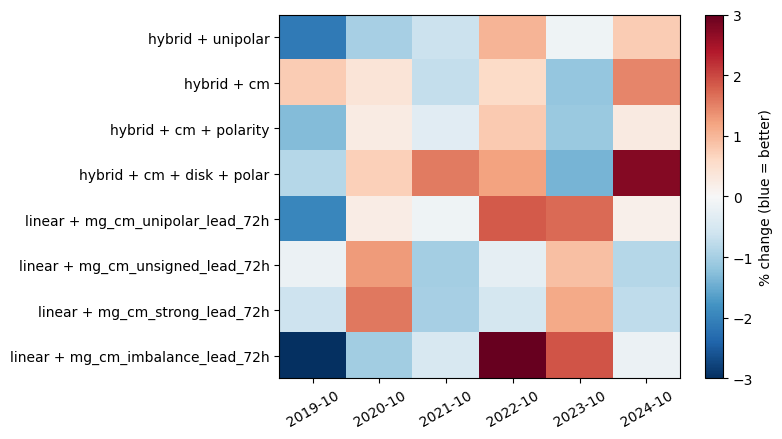

In [4]:
change = pd.DataFrame({
    n: 100 * (df[n] / df["hybrid shipped" if n.startswith("hybrid") else "linear shipped"] - 1)
    for n in m.variant_names()[1:]})
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(change.T.to_numpy(), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_yticks(range(change.shape[1]), change.columns)
ax.set_xticks(range(change.shape[0]), change.index, rotation=30)
plt.colorbar(im, label="% change (blue = better)")
plt.tight_layout()
display(change.T.round(2))

## 4. CME runs and the rest (% change against the shipped model, per fold)

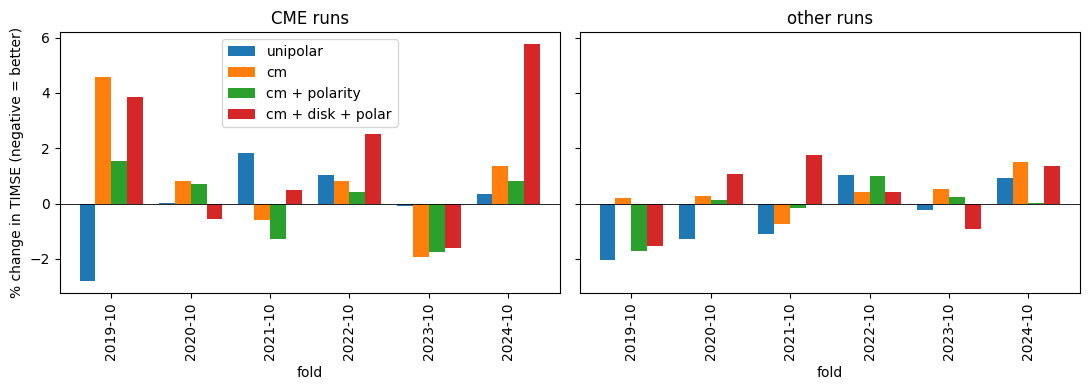

In [5]:
hyb = [n for n in m.variant_names()[1:] if n.startswith("hybrid")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, part in zip(axes, ("cme", "other"), strict=True):
    tab = pd.DataFrame({n.removeprefix("hybrid + "): 100 * (df[f"{n} {part}"] - 1) for n in hyb})
    tab.plot.bar(ax=ax, width=0.8, legend=part == "cme")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"{'CME' if part == 'cme' else 'other'} runs")
    ax.set_ylabel("% change in TIMSE (negative = better)")
plt.tight_layout()

## 5. Findings

**Not built.** The best set (hybrid + unipolar) gains 0.36% (4 of 6 folds), against a bar of 1% and 4 of 6; the linear-model terms move the score by at most 0.04%.

- **The images don't show coronal holes.** The browse JPEGs are 8-bit, with a range set for active regions, so a coronal hole's few-gauss net field is lost. With the solar-cycle trend removed, the strip's unipolarity is uncorrelated with the AIA coronal-hole fraction and with later speed (section 1); only the strong-field imbalance tracks speed (r = 0.16, against 0.32 for `ch_cm`).
- **The gain doesn't hold.** The unipolar set gains in 2019-10 to 2021-10 and loses in 2022-10 and 2024-10 (section 3).
- **More features, worse trees.** Active-region numbers are mostly a solar-cycle clock that F10.7 and the flare counts already give the trees.
- **No help on CME runs** (section 4).

**Decision:** the magnetogram route closes at path (i); the PFSS/WSA build is not started. A path (ii) model on the same images would face the same limit. A real step needs a calibrated magnetogram (GONG or the HMI FITS), which this network can't reach. See `docs/magnetogram.md`.